In [59]:
import numpy as np
import pandas as pd
import time

In [60]:
"""3D transport-connectivity-aware binary downsampling.

IMPORTANT: This is an *adaptation inspired by* the constrained-selection
principle in Chen & Peng, ECCV 2024, NOT their published algorithm.
Their formulation and topology-preservation guarantee are 2D only.

This implementation guarantees (subject to sufficient volume budget) that
at least k requested face-connected inlet->outlet paths through original
spanning components are retained as 6-connected coarse paths. It preserves
whole-volume foreground fraction to the nearest coarse-grid voxel.

It does NOT preserve all 3D Betti numbers (components, loops, cavities),
all original connections, or effective conductivity. Review results!

Dependencies: numpy, scipy, scikit-image.
"""

import argparse
import numpy as np
from scipy import ndimage as ndi
from skimage.graph import MCP_Geometric


FACE6 = ndi.generate_binary_structure(3, 1)


def nearest_factor(shape, requested):
    """Nearest isotropic *integer* block factor dividing all 3 dimensions."""
    requested = float(requested)
    if requested < 1 or not np.isfinite(requested):
        raise ValueError("factor must be a finite number >= 1")
    valid = [b for b in range(1, min(shape) + 1)
             if all(s % b == 0 for s in shape)]
    return min(valid, key=lambda b: (abs(b - requested), b))


def _block_mean(mask, b):
    shape = mask.shape
    return mask.reshape(
        shape[0] // b, b,
        shape[1] // b, b,
        shape[2] // b, b,
    ).mean(axis=(1, 3, 5))


def _spanning_component_ids(labels, axis):
    lo = np.unique(np.take(labels, 0, axis=axis))
    hi = np.unique(np.take(labels, -1, axis=axis))
    return np.intersect1d(lo[lo > 0], hi[hi > 0])


def transport_preserving_downsample_3d(
    binary,
    factor=2,
    transport_axis=0,
    paths_per_component=12,
    reuse_penalty=8.0,
    seed=0,
):
    """Downsample, protecting several coarse paths for each spanning component.

    Parameters
    ----------
    binary : array, shape (Z,Y,X) or any other consistent axis convention
        True/1 means conducting phase; exactly two phases (binary) supported.
    factor : float
        Requested integer *block coarsening factor*. Nearest common divisor
        of input dimensions is used if unavailable (e.g. 96^3 + factor 5 -> 4).
    transport_axis : int
        0, 1, or 2, following your NumPy array axis order.
    paths_per_component : int
        How many preferentially *different* inlet-to-outlet coarse paths to
        protect for each inlet-outlet-spanning original component.
    reuse_penalty : float
        Extra cost multiplier on already protected coarse cells, encourages
        distinct routes. Paths can overlap at unavoidable thin connections.
    seed : int
        Tie-breaking seed.

    Returns
    -------
    coarse : bool ndarray
    report : dict
    """
    a = np.asarray(binary)
    if a.ndim != 3 or not np.isin(np.unique(a), [0, 1]).all():
        raise ValueError("Input must be a 3D binary (0/1 or bool) array")
    a = a.astype(bool, copy=False)

    axis = int(transport_axis)
    if axis not in (0, 1, 2):
        raise ValueError("transport_axis must be 0, 1, or 2")
    if not isinstance(paths_per_component, (int, np.integer)) or paths_per_component < 1:
        raise ValueError("paths_per_component must be a positive integer")
    if reuse_penalty < 0:
        raise ValueError("reuse_penalty cannot be negative")

    b = nearest_factor(a.shape, factor)
    if b == 1:
        return a.copy(), {
            'factor_used': 1, 'input_shape': a.shape,
            'output_shape': a.shape, 'original_volume_fraction': float(a.mean()),
            'coarse_volume_fraction': float(a.mean()),
            'protected_voxels': 0, 'original_spanning_components': None,
            'coarse_spanning_components': None, 'paths_protected': 0,
        }

    coarse_shape = tuple(n // b for n in a.shape)
    occupancy = _block_mean(a, b)
    target = int(round(float(a.mean()) * occupancy.size))

    original_labels, _ = ndi.label(a, structure=FACE6)
    original_spanning = _spanning_component_ids(original_labels, axis)
    protected = np.zeros(coarse_shape, dtype=bool)
    paths_found = 0

    for component_id in original_spanning:
        # Blocks intersecting this original 6-connected component are
        # necessarily 6-connected and reach both transport boundaries.
        component_fraction = _block_mean(original_labels == component_id, b)
        candidate = component_fraction > 0

        candidate_coords = np.argwhere(candidate)
        inlet_coords = candidate_coords[candidate_coords[:, axis] == 0]
        outlet_coords = candidate_coords[
            candidate_coords[:, axis] == coarse_shape[axis] - 1
        ]

        if not len(inlet_coords) or not len(outlet_coords):
            raise RuntimeError("Original spanning component lost on projection")

        use_counts = np.zeros(coarse_shape, dtype=np.float32)
        # Base cost rewards blocks occupied strongly by this component;
        # finite only where the original component occurs within the block.
        base_cost = np.full(coarse_shape, np.inf, dtype=np.float64)
        base_cost[candidate] = 1.0 / np.maximum(
            component_fraction[candidate], 1.0 / b**3
        )

        ends = [tuple(p) for p in outlet_coords]
        starts = [tuple(p) for p in inlet_coords]

        for _ in range(paths_per_component):
            cost = base_cost * (1.0 + reuse_penalty * use_counts)
            solver = MCP_Geometric(cost, fully_connected=False)
            distances, _ = solver.find_costs(starts=starts, ends=ends,
                                             find_all_ends=False)
            end_distances = distances[tuple(outlet_coords.T)]
            j = int(np.argmin(end_distances))
            if not np.isfinite(end_distances[j]):
                raise RuntimeError("Could not find a projected connected path")
            route = np.asarray(solver.traceback(ends[j]), dtype=int)
            if not np.all(candidate[tuple(route.T)]):
                raise AssertionError("Internal routing error: path left component")
            protected[tuple(route.T)] = True
            use_counts[tuple(route.T)] += 1
            paths_found += 1

    protected_n = int(protected.sum())
    if protected_n > target:
        raise ValueError(
            f"Cannot meet fixed phase fraction: {protected_n} protected "
            f"coarse voxels, but only {target} allowed. Reduce "
            "paths_per_component or the coarsening factor."
        )

    coarse = protected.ravel().copy()
    available = np.flatnonzero(~coarse)
    need = target - protected_n
    rng = np.random.default_rng(seed)
    if need:
        # Block occupancy is the similarity objective. Small random noise
        # only resolves occupancy ties; it cannot reorder non-tied blocks.
        scores = occupancy.ravel()[available] + (
            rng.random(len(available)) * 1e-3 / b**3
        )
        selection = np.argpartition(scores, -need)[-need:]
        coarse[available[selection]] = True

    coarse = coarse.reshape(coarse_shape)
    coarse_labels, _ = ndi.label(coarse, structure=FACE6)
    coarse_spanning = _spanning_component_ids(coarse_labels, axis)
    if len(original_spanning) and not len(coarse_spanning):
        raise AssertionError("Protected path disconnected; check code")

    return coarse, {
        'factor_requested': float(factor),
        'factor_used': b,
        'input_shape': a.shape,
        'output_shape': coarse.shape,
        'transport_axis': axis,
        'original_volume_fraction': float(a.mean()),
        'coarse_volume_fraction': float(coarse.mean()),
        'volume_fraction_error': float(coarse.mean() - a.mean()),
        'original_spanning_components': len(original_spanning),
        'coarse_spanning_components': len(coarse_spanning),
        'protected_voxels': protected_n,
        'paths_protected': paths_found,
    }


def _synthetic_test_data(n=96):
    """Two conducting chambers linked by an extremely thin conducting neck."""
    x, y, z = np.ogrid[:n, :n, :n]
    center = n // 2
    # Fat conducting regions touch opposing x boundaries.
    left = (x <= n * .30) & ((y-center)**2 + (z-center)**2 < (n*.19)**2)
    right = (x >= n * .70) & ((y-center)**2 + (z-center)**2 < (n*.19)**2)
    thin = ((y-center)**2 + (z-center)**2 <= 1)  # 5-voxel cross section
    return left | right | thin

In [14]:
"""Compare four binary 3D downsampling approaches for porous microstructures.

Dependencies: numpy, scipy, scikit-image and the sibling module
`transport_preserving_downsample_3d.py` supplied in this conversation.

Methods:
  - resize: nearest-neighbor skimage.resize (optional VF adjustment)
  - rescale: anti-aliased linear skimage.rescale
  - downscale: exact block occupancy skimage.downscale_local_mean
  - topology: transport-path-aware 3D downsampling adaptation

Note: topology method only protects selected inlet-outlet paths, not full 3D topology.
"""
import numpy as np
from scipy import ndimage as ndi
from skimage.transform import resize, rescale, downscale_local_mean

def _select_fixed_volume(scores, original_volume_fraction, seed=0):
    """Set the nearest possible number of high-score voxels to 1."""
    scores = np.asarray(scores, dtype=np.float64)
    count = round(original_volume_fraction * scores.size)
    if count == 0:
        return np.zeros(scores.shape, dtype=bool)
    if count == scores.size:
        return np.ones(scores.shape, dtype=bool)

    # Resolve exact occupancy / intensity ties reproducibly.
    rng = np.random.default_rng(seed)
    noise = rng.random(scores.size) * 1e-12
    ranked = scores.ravel() + noise
    selected = np.argpartition(ranked, -count)[-count:]
    result = np.zeros(scores.size, dtype=bool)
    result[selected] = True
    return result.reshape(scores.shape)


def _spanning_components(binary, axis):
    structure = ndi.generate_binary_structure(3, 1)
    labels, _ = ndi.label(binary, structure=structure)
    first = np.unique(np.take(labels, 0, axis=axis))
    last = np.unique(np.take(labels, -1, axis=axis))
    return len(np.intersect1d(first[first > 0], last[last > 0]))


def compare_downsampling(
    binary,
    factor=2,
    transport_axis=0,
    match_volume_fraction=True,
    paths_per_component=12,
    seed=0,
):
    """Return (outputs, summary) for four downsampling methods.

    The same isotropic block factor is used for all methods; if it is not a
    common divisor of all dimensions, use the nearest valid common divisor.

    When match_volume_fraction=True, regular rescale/downscale results are
    binarized by choosing the highest scores up to the original phase fraction.
    The nearest-neighbor resize is adjusted minimally: its original binary
    classification has priority and coarse-block occupancy breaks ties. Turn
    this option off for unmodified nearest-neighbor/0.5-threshold baselines.

    Returns
    -------
    outputs: dict[str, bool ndarray]
        'resize', 'rescale', 'downscale', 'topology'.
    summary: dict
        Factor, original and output volume fractions, and 6-connected
        inlet-to-outlet spanning component counts. The topology method's
        additional diagnostics are under 'topology_report'.
    """
    arr = np.asarray(binary)
    if arr.ndim != 3 or not np.isin(arr, [0, 1]).all():
        raise ValueError("binary must be a 3D 0/1 or boolean ndarray")
    if transport_axis not in (0, 1, 2):
        raise ValueError("transport_axis must be 0, 1, or 2")

    x = arr.astype(bool)
    b = nearest_factor(x.shape, factor)
    target_shape = tuple(s // b for s in x.shape)
    target_vf = float(x.mean())
    x_float = x.astype(np.float32)

    # A) Resize: nearest-neighbor; no smoothing.
    resize_raw = resize(
        x_float, target_shape, order=0, anti_aliasing=False,
        preserve_range=True, mode='reflect',
    )

    # B) Rescale: linear interpolation with Gaussian anti-alias filtering.
    rescale_scores = rescale(
        x_float, scale=1.0 / b, order=1, anti_aliasing=(b > 1),
        preserve_range=True, mode='reflect', channel_axis=None,
    )
    if rescale_scores.shape != target_shape:
        raise RuntimeError(
            f"rescale produced {rescale_scores.shape}, expected {target_shape}"
        )

    # C) Downscale: exact average occupancy in each b x b x b block.
    block_scores = downscale_local_mean(x_float, (b, b, b))

    if match_volume_fraction:
        # Preserve nearest-neighbor classification unless adjustment is needed;
        # then favor coarse voxels with higher original block occupancy.
        resize_scores = resize_raw + 0.25 * block_scores
        resized = _select_fixed_volume(resize_scores, target_vf, seed)
        rescaled = _select_fixed_volume(rescale_scores, target_vf, seed)
        downscaled = _select_fixed_volume(block_scores, target_vf, seed)
    else:
        resized = resize_raw >= 0.5
        rescaled = rescale_scores >= 0.5
        downscaled = block_scores >= 0.5

    # D) Topology: protect multiple original through-connected paths.
    topology, topology_report = transport_preserving_downsample_3d(
        x, factor=b, transport_axis=transport_axis,
        paths_per_component=paths_per_component, seed=seed,
    )

    outputs = {
        'resize': resized.astype(bool),
        'rescale': rescaled.astype(bool),
        'downscale': downscaled.astype(bool),
        'topology': topology.astype(bool),
    }

    summary = {
        'factor_used': b,
        'input_shape': x.shape,
        'output_shape': target_shape,
        'original_volume_fraction': target_vf,
        'original_spanning_components': _spanning_components(x, transport_axis),
        'methods': {
            name: {
                'volume_fraction': float(img.mean()),
                'volume_fraction_error': float(img.mean() - target_vf),
                'spanning_components': _spanning_components(img, transport_axis),
            }
            for name, img in outputs.items()
        },
        'topology_report': topology_report,
    }
    return outputs, summary


In [17]:
data1 = (np.load("../../data_new/Fine_microstructure_0/segmented_percolated.npy")==3)

In [18]:
outputs, summary = compare_downsampling(
    data1,
    factor=2,
    transport_axis=0,
    match_volume_fraction=True,
    paths_per_component=12,
    seed=0,
)

# Four downsampled binary images
img_resize = outputs["resize"]
img_rescale = outputs["rescale"]
img_downscale = outputs["downscale"]
img_topology = outputs["topology"]

for name, img in outputs.items():
    print(
        name,
        img.shape,
        "VF:", img.mean(),
        "Spanning:", summary["methods"][name]["spanning_components"]
    )


resize (75, 75, 75) VF: 0.4663703703703704 Spanning: 1
rescale (75, 75, 75) VF: 0.4663703703703704 Spanning: 1
downscale (75, 75, 75) VF: 0.4663703703703704 Spanning: 1
topology (75, 75, 75) VF: 0.4663703703703704 Spanning: 1


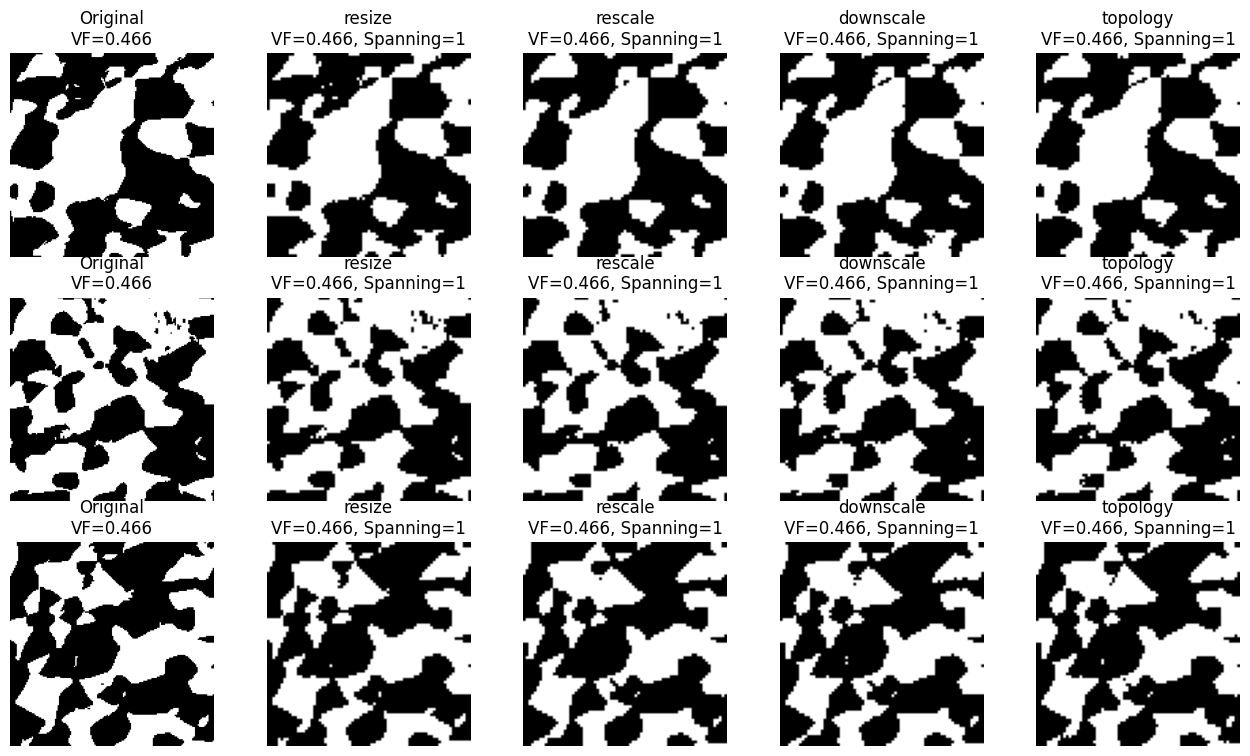

In [24]:
fig, ax = plt.subplots(3, 5, figsize=(16, 9))

for x in range(3):
    ax[x, 0].imshow(data1[int((data1.shape[0]//3)*(x+1))-1], cmap="gray", vmin=0, vmax=1)
    ax[x, 0].set_title(f"Original\nVF={data1.mean():.3f}")
    ax[x, 0].axis("off")

for x in range(3):
    for i, (name, img) in enumerate(outputs.items()):
        ax[x,i+1].imshow(img[int(img.shape[0]//3*(x+1))-1], cmap="gray", vmin=0, vmax=1)
        ax[x,i+1].set_title(f"{name}\nVF={img.mean():.3f}, "
                        f"Spanning={summary['methods'][name]['spanning_components']}")
        ax[x,i+1].axis("off")

Text(0.5, 1.0, 'Downsampled')

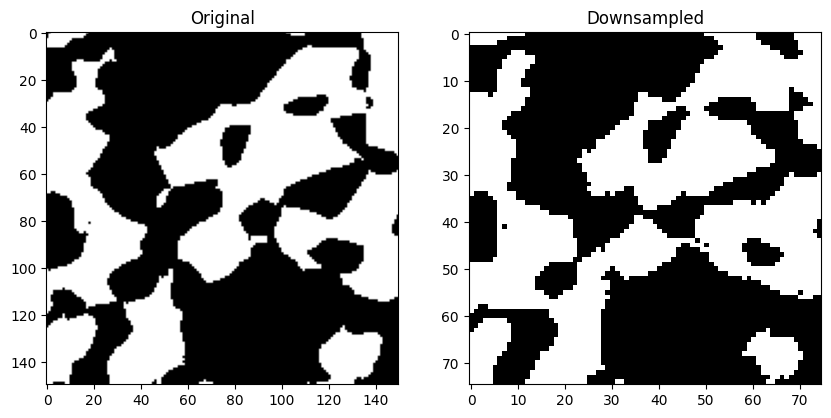

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

orig = data_1[3]
ds = data_1_df2[0][3]

ax[0].imshow(orig, cmap='gray')
ax[0].set_title('Original')

ax[1].imshow(ds, cmap='gray')
ax[1].set_title('Downsampled')

In [29]:
import numpy as np
import taufactor as tau


def solve_taufactor(
    binary,
    transport_axis=0,
    periodic=False,
    device="cpu",
    conv_crit=1e-4,
    iter_limit=50000,
    save_full=True,
):
    """
    Run TauFactor and calculate cell-centered flux,
    flux-reconciled tortuosity, and constrictivity.

    Parameters
    ----------
    binary : np.ndarray
        3D binary image (1=conducting, 0=insulating).

    transport_axis : int
        Transport direction in ORIGINAL array (0, 1, 2).

    periodic : bool
        False: no-flux transverse boundaries.
        True: periodic transverse boundaries.

    device : str
        "cpu" or "cuda".

    conv_crit : float
        TauFactor convergence criterion.

    iter_limit : int
        Maximum solver iterations.

    save_full : bool
        Return potential, pore mask, and flux arrays.

    Returns
    -------
    dict
        Scalar transport metrics and optionally full fields.
    """

    img = np.asarray(binary)

    if img.ndim != 3:
        raise ValueError("Expected a 3D image.")

    if transport_axis not in (0, 1, 2):
        raise ValueError("transport_axis must be 0, 1, or 2.")

    if not np.isin(img, [0, 1]).all():
        raise ValueError("Input must contain only 0 and 1.")

    # --------------------------------------------------
    # 1. Move transport direction to TauFactor axis 0
    # --------------------------------------------------
    work = np.ascontiguousarray(
        np.moveaxis(img, transport_axis, 0),
        dtype=np.uint8
    )

    pore_mask = work == 1

    # --------------------------------------------------
    # 2. Solve
    # --------------------------------------------------
    SolverClass = (
        tau.PeriodicSolver if periodic else tau.Solver
    )

    solver = SolverClass(work, D_0=1.0, device=device)

    solver.solve(
        iter_limit=iter_limit,
        conv_crit=conv_crit,
        verbose=False
    )

    if not solver.converged:
        raise RuntimeError(
            f"TauFactor did not converge after "
            f"{solver.iter} iterations."
        )

    D_eff = float(solver.D_eff[0])
    tau_solver = float(solver.tau[0])

    # --------------------------------------------------
    # 3. Extract interior potential
    # --------------------------------------------------
    phi = (
        solver.field[0, 1:-1, 1:-1, 1:-1]
        .detach()
        .cpu()
        .numpy()
    )

    # TauFactor: [-0.5, +0.5]
    # RN convention: [1, 0]
    potential_rn = 0.5 - phi

    # --------------------------------------------------
    # 4. Calculate cell-centered flux
    # --------------------------------------------------
    # Uses +gradient of TauFactor potential.
    # Equivalent to -gradient of RN-convention potential.
    #
    # This reproduces your internal-face averaging method.
    # Flux here is unscaled by the physical voxel pitch.

    def centered_flux(field, mask, axis, periodic_axis=False):

        if periodic_axis:
            # Include the face connecting the last and
            # first cells along a periodic direction.
            F = np.roll(field, -1, axis=axis) - field

            face_mask = mask & np.roll(
                mask, -1, axis=axis
            )

            F = np.where(face_mask, F, 0.0)

            return 0.5 * (
                F + np.roll(F, 1, axis=axis)
            )

        # Internal neighbor differences
        F = np.diff(field, axis=axis)

        s0 = [slice(None)] * 3
        s1 = [slice(None)] * 3

        s0[axis] = slice(None, -1)
        s1[axis] = slice(1, None)

        face_mask = (
            mask[tuple(s0)] & mask[tuple(s1)]
        )

        F = np.where(face_mask, F, 0.0)

        # Average adjacent face fluxes at cell centers.
        # Outer missing faces contribute zero, matching
        # your original calculation.
        pad_before = [(0, 0)] * 3
        pad_after = [(0, 0)] * 3

        pad_before[axis] = (1, 0)
        pad_after[axis] = (0, 1)

        return 0.5 * (
            np.pad(F, pad_before)
            + np.pad(F, pad_after)
        )

    # Flux components in TauFactor's working coordinates
    J_work = [
        centered_flux(phi, pore_mask, axis=0),
        centered_flux(
            phi, pore_mask, axis=1,
            periodic_axis=periodic
        ),
        centered_flux(
            phi, pore_mask, axis=2,
            periodic_axis=periodic
        ),
    ]

    J0, J1, J2 = J_work

    J_mag = np.sqrt(J0**2 + J1**2 + J2**2)

    # --------------------------------------------------
    # 5. Flux-reconciled tortuosity
    # --------------------------------------------------
    # J0 is ALWAYS the transport-direction flux
    # in TauFactor working coordinates.

    if np.any(pore_mask):
        flux_average_pore = float(
            np.mean(J_mag[pore_mask])
        )

        flux_x_average_pore = float(
            np.abs(np.mean(J0[pore_mask]))
        )
    else:
        flux_average_pore = 0.0
        flux_x_average_pore = 0.0

    if flux_x_average_pore > 0:
        tau_reconciled = (
            flux_average_pore / flux_x_average_pore
        )
    else:
        tau_reconciled = np.nan

    # --------------------------------------------------
    # 6. Constrictivity
    # --------------------------------------------------
    if (
        np.isfinite(tau_reconciled)
        and np.isfinite(tau_solver)
        and tau_solver > 0
    ):
        constrictivity = (
            tau_reconciled**2 / tau_solver
        )
    else:
        constrictivity = np.nan

    # --------------------------------------------------
    # 7. Collect scalar results
    # --------------------------------------------------
    results = {
        "D_eff_rel": D_eff,
        "D_eff": D_eff,
        "tau": tau_solver,
        "tau_solver": tau_solver,
        "tau_reconciled": float(tau_reconciled),
        "constrictivity": float(constrictivity),

        "volume_fraction": float(img.mean()),
        "porosity": float(img.mean()),

        "flux_average_pore": flux_average_pore,
        "flux_x_average_pore": flux_x_average_pore,
        "converged": bool(solver.converged),
        "iterations": solver.iter,
    }

    # --------------------------------------------------
    # 8. Restore original image coordinate system
    # --------------------------------------------------
    if save_full:

        def restore(arr):
            return np.moveaxis(
                arr, 0, transport_axis
            )

        # After moveaxis, the component axes must
        # also be mapped back to their original labels.
        #
        # Example: transport_axis=2
        # working axes = [original Z, original X, original Y]

        original_order = [
            transport_axis,
            *[a for a in range(3) if a != transport_axis]
        ]

        J_original = [None, None, None]

        for work_axis, original_axis in enumerate(original_order):
            J_original[original_axis] = restore(
                J_work[work_axis]
            )

        results.update({
            "potential": restore(potential_rn),
            "potential_field": restore(potential_rn),
            "pore_mask": restore(pore_mask),

            "J_x": J_original[0],
            "J_y": J_original[1],
            "J_z": J_original[2],
            "J_mag": restore(J_mag),

            "J_transport": J_original[transport_axis],
        })

    return results

In [44]:
"""Four binary 3D downsampling methods at arbitrary target resolutions.

The 'topology' option protects selected inlet/outlet paths, NOT all 3D topology.
Dependencies: numpy, scipy, scikit-image.
"""
import numpy as np
from scipy import ndimage as ndi
from scipy.sparse import csr_matrix
from skimage.transform import resize, rescale
from skimage.graph import MCP_Geometric


def _axis_weights(n, m):
    """Exact fractional overlaps of m output intervals with n input intervals."""
    rows, cols, vals = [], [], []
    width = n / m
    for j in range(m):
        left, right = j * width, (j + 1) * width
        for i in range(int(np.floor(left)), min(n, int(np.ceil(right)))):
            overlap = max(0., min(right, i + 1) - max(left, i))
            if overlap > 0:
                rows.append(j); cols.append(i); vals.append(overlap / width)
    return csr_matrix((vals, (rows, cols)), shape=(m, n))


def area_occupancy(binary, shape):
    """Exact box-overlap volume average, including fractional edge voxels."""
    out = np.asarray(binary, dtype=np.float64)
    for axis, m in enumerate(shape):
        w = _axis_weights(out.shape[axis], m)
        out = np.moveaxis(out, axis, 0)
        old_shape = out.shape
        out = (w @ out.reshape(old_shape[0], -1)).reshape((m,) + old_shape[1:])
        out = np.moveaxis(out, 0, axis)
    return out


def _fixed_vf(scores, vf, seed=0):
    scores = np.asarray(scores)
    k = int(round(vf * scores.size))
    out = np.zeros(scores.size, dtype=bool)
    if k:
        if k == scores.size:
            out[:] = True
        else:
            rng = np.random.default_rng(seed)
            rank = scores.ravel() + 1e-12 * rng.random(scores.size)
            out[np.argpartition(rank, -k)[-k:]] = True
    return out.reshape(scores.shape)


def _spanning_ids(labels, axis):
    a = np.unique(np.take(labels, 0, axis=axis))
    b = np.unique(np.take(labels, -1, axis=axis))
    return np.intersect1d(a[a > 0], b[b > 0])


def topology_coarsen(binary, shape, axis=0, paths_per_component=12,
                     reuse_penalty=8., seed=0, occupancy=None):
    """Protect selected 6-connected through-paths; preserve total binary VF."""
    x = np.asarray(binary, dtype=bool)
    if occupancy is None:
        occupancy = area_occupancy(x, shape)
    labels, _ = ndi.label(x, structure=ndi.generate_binary_structure(3, 1))
    spanning = _spanning_ids(labels, axis)
    protected = np.zeros(shape, dtype=bool)
    paths = 0
    for label in spanning:
        frac = area_occupancy(labels == label, shape)
        candidate = frac > 1e-14
        coords = np.argwhere(candidate)
        starts = [tuple(c) for c in coords[coords[:, axis] == 0]]
        ends_arr = coords[coords[:, axis] == shape[axis] - 1]
        ends = [tuple(c) for c in ends_arr]
        if not starts or not ends:
            raise RuntimeError('Original spanning component did not project to both faces')
        base = np.full(shape, np.inf)
        base[candidate] = 1. / frac[candidate]
        counts = np.zeros(shape)
        for _ in range(paths_per_component):
            cost = np.where(candidate, base * (1. + reuse_penalty * counts), np.inf)
            graph = MCP_Geometric(cost, fully_connected=False)
            distances, _ = graph.find_costs(starts=starts, ends=ends, find_all_ends=False)
            j = int(np.argmin(distances[tuple(ends_arr.T)]))
            end = ends[j]
            if not np.isfinite(distances[end]):
                raise RuntimeError('No coarse face-connected path found')
            route = np.asarray(graph.traceback(end), dtype=int)
            protected[tuple(route.T)] = True
            counts[tuple(route.T)] += 1
            paths += 1
    k = int(round(x.mean() * np.prod(shape)))
    n = int(protected.sum())
    if n > k:
        raise ValueError(f'Protected paths require {n} voxels, budget is {k}. Reduce paths_per_component.')
    result = protected.ravel().copy()
    available = np.flatnonzero(~result)
    need = k - n
    if need:
        rng = np.random.default_rng(seed)
        scores = occupancy.ravel()[available] + 1e-12 * rng.random(len(available))
        result[available[np.argpartition(scores, -need)[-need:]]] = True
    result = result.reshape(shape)
    coarse_labels, _ = ndi.label(result, structure=ndi.generate_binary_structure(3, 1))
    if len(spanning) and not len(_spanning_ids(coarse_labels, axis)):
        raise RuntimeError('Coarse spanning path lost')
    return result, {'protected_voxels': n, 'paths_selected': paths,
                    'original_spanning_components': len(spanning),
                    'coarse_spanning_components': len(_spanning_ids(coarse_labels, axis))}


def compare_downsampling(binary, factor=2., transport_axis=0,
                         match_volume_fraction=True, paths_per_component=12,
                         seed=0):
    """Return (outputs, summary). Factor > 1 means downsampling."""
    x = np.asarray(binary)
    if x.ndim != 3 or not np.isin(x, [0, 1]).all():
        raise ValueError('binary must be 3D containing only 0 and 1')
    if not np.isfinite(factor) or factor < 1:
        raise ValueError('factor must be finite and >= 1')
    if transport_axis not in (0, 1, 2):
        raise ValueError('transport_axis must be 0, 1, or 2')
    x = x.astype(bool)
    shape = tuple(max(1, int(np.floor(n / factor + 0.5))) for n in x.shape)
    vf = float(x.mean())
    scores = area_occupancy(x, shape)
    nearest = resize(x.astype(float), shape, order=0, anti_aliasing=False, preserve_range=True)
    # rescale uses a scalar scale, then enforce exactly the same target shape.
    scaled = rescale(x.astype(float), scale=1. / factor, order=1,
                     anti_aliasing=factor > 1, preserve_range=True, channel_axis=None)
    if scaled.shape != shape:
        scaled = resize(x.astype(float), shape, order=1,
                        anti_aliasing=factor > 1, preserve_range=True)
    if match_volume_fraction:
        # Preserve nearest-neighbor decisions preferentially; use occupancy for ties.
        resized = _fixed_vf(nearest + 0.25 * scores, vf, seed)
        rescaled = _fixed_vf(scaled, vf, seed)
        downscaled = _fixed_vf(scores, vf, seed)
    else:
        resized = nearest >= 0.5
        rescaled = scaled >= 0.5
        downscaled = scores >= 0.5
    topology, report = topology_coarsen(x, shape, axis=transport_axis,
                                        paths_per_component=paths_per_component,
                                        seed=seed, occupancy=scores)
    outputs = {'resize': resized, 'rescale': rescaled,
               'downscale': downscaled, 'topology': topology}
    summary = {'factor_requested': float(factor), 'input_shape': x.shape,
               'output_shape': shape, 'effective_factors': tuple(n / m for n, m in zip(x.shape, shape)),
               'original_volume_fraction': vf, 'topology_report': report,
               'methods': {name: {'volume_fraction': float(img.mean()),
                                  'spanning_components': len(_spanning_ids(
                                      ndi.label(img, structure=ndi.generate_binary_structure(3, 1))[0],
                                      transport_axis))}
                           for name, img in outputs.items()}}
    return outputs, summary


In [46]:
# Change this list as needed; previously computed factors remain cached.
factors = [1.25, 1.5, 2.0, 3.0, 4.0, 8.0]

if "_downsampling_cache" not in globals():
    _downsampling_cache = {}

methods = ["resize", "rescale", "downscale", "topology"]
records = []

for factor in factors:
    key = (float(factor), 0, False, True, 12, 0)

    if key not in _downsampling_cache:
        _downsampling_cache[key] = compare_downsampling(
            data1,
            factor=factor,
            transport_axis=0,
            match_volume_fraction=False,
            paths_per_component=12,
            seed=0,
        )

    factor_outputs, factor_summary = _downsampling_cache[key]

    for method in methods:
        result = solve_taufactor(
            factor_outputs[method],
            transport_axis=0,
            periodic=False,
            save_full=False,
        )

        records.append({
            "factor": float(factor),
            "method": method,
            "shape": factor_outputs[method].shape,
            "volume_fraction": float(factor_outputs[method].mean()),
            "D_eff": result["D_eff"],
            "tau": result["tau"],
            "tau_reconciled": result["tau_reconciled"],
            "constrictivity": result["constrictivity"],
        })

df_transport = pd.DataFrame(records).sort_values(
    ["factor", "method"]
).reset_index(drop=True)

# A separate dataframe for each method
df_resize = df_transport[df_transport["method"] == "resize"].reset_index(drop=True)
df_rescale = df_transport[df_transport["method"] == "rescale"].reset_index(drop=True)
df_downscale = df_transport[df_transport["method"] == "downscale"].reset_index(drop=True)
df_topology = df_transport[df_transport["method"] == "topology"].reset_index(drop=True)

df_transport


,factor,method,shape,volume_fraction,D_eff,tau,tau_reconciled,constrictivity
0,1.25,downscale,"(120, 120, 120)",0.466395,0.180173,2.588591,1.274844,0.627843
1,1.25,rescale,"(120, 120, 120)",0.466508,0.179744,2.595405,1.275553,0.626891
2,1.25,resize,"(120, 120, 120)",0.466480,0.179117,2.604335,1.275800,0.624983
3,1.25,topology,"(120, 120, 120)",0.466372,0.180173,2.588469,1.274819,0.627847
4,1.50,downscale,"(100, 100, 100)",0.466142,0.176901,2.635042,1.277001,0.618863
5,1.50,rescale,"(100, 100, 100)",0.466154,0.176373,2.642997,1.277727,0.617703
6,1.50,resize,"(100, 100, 100)",0.466259,0.175829,2.651778,1.279039,0.616922
7,1.50,topology,"(100, 100, 100)",0.466372,0.177129,2.632945,1.276710,0.619075
8,2.00,downscale,"(75, 75, 75)",0.479301,0.183464,2.612508,1.272937,0.620235
9,2.00,rescale,"(75, 75, 75)",0.466373,0.174983,2.665248,1.279011,0.613777


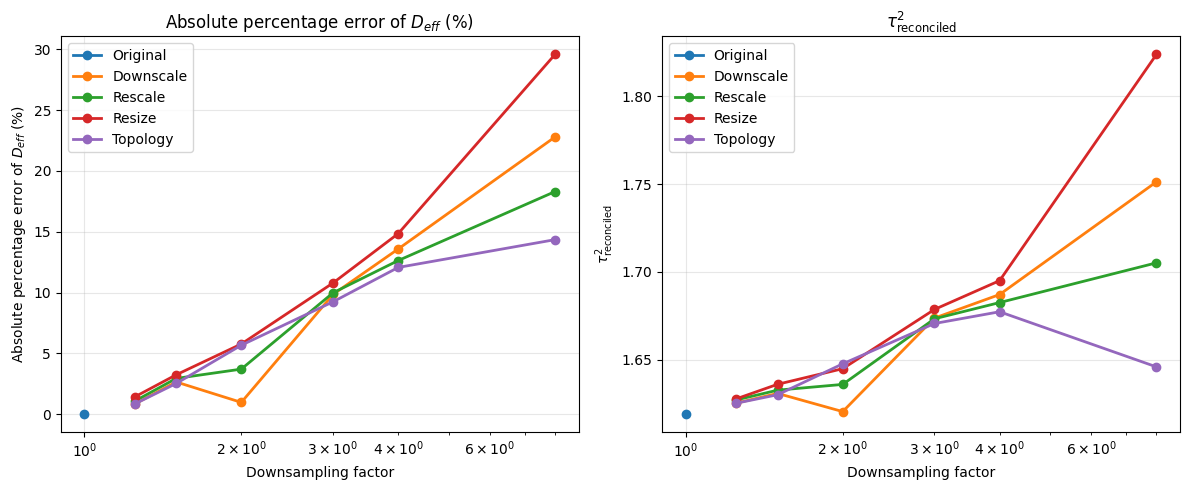

In [49]:
df_transport_plot = pd.concat(
    [original_row, df_transport],
    ignore_index=True,
).copy()

reference_d_eff = original_result["D_eff"]

df_transport_plot["D_eff_abs_percentage_error"] = (
    (df_transport_plot["D_eff"] - reference_d_eff).abs()
    / abs(reference_d_eff)
    * 100
)

df_transport_plot["tau_reconciled_squared"] = (
    df_transport_plot["tau_reconciled"] ** 2
)

metrics = [
    ("D_eff_abs_percentage_error", "Absolute percentage error of $D_{eff}$ (%)"),
    ("tau_reconciled_squared", r"$\tau_{\mathrm{reconciled}}^2$"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

for ax, (metric, ylabel) in zip(axes, metrics):
    for method, group in df_transport_plot.groupby("method", sort=False):
        group = group.sort_values("factor")
        ax.plot(
            group["factor"],
            group[metric],
            marker="o",
            linewidth=2,
            label=method.capitalize(),
        )

    ax.set_title(ylabel)
    ax.set_xlabel("Downsampling factor")
    ax.set_ylabel(ylabel)
    ax.set_xscale("log")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()


In [53]:
import glob

files = sorted(glob.glob("../../data_new/Fine_microstructure_*/*percolated*.npy"))
files

['../../data_new/Fine_microstructure_0/segmented_percolated.npy',
 '../../data_new/Fine_microstructure_1/segmented_percolated.npy',
 '../../data_new/Fine_microstructure_2/segmented_percolated.npy',
 '../../data_new/Fine_microstructure_3/segmented_percolated.npy',
 '../../data_new/Fine_microstructure_4/segmented_percolated.npy',
 '../../data_new/Fine_microstructure_5/segmented_percolated.npy',
 '../../data_new/Fine_microstructure_6/segmented_percolated.npy',
 '../../data_new/Fine_microstructure_7/segmented_percolated.npy',
 '../../data_new/Fine_microstructure_8/segmented_percolated.npy',
 '../../data_new/Fine_microstructure_9/segmented_percolated.npy']

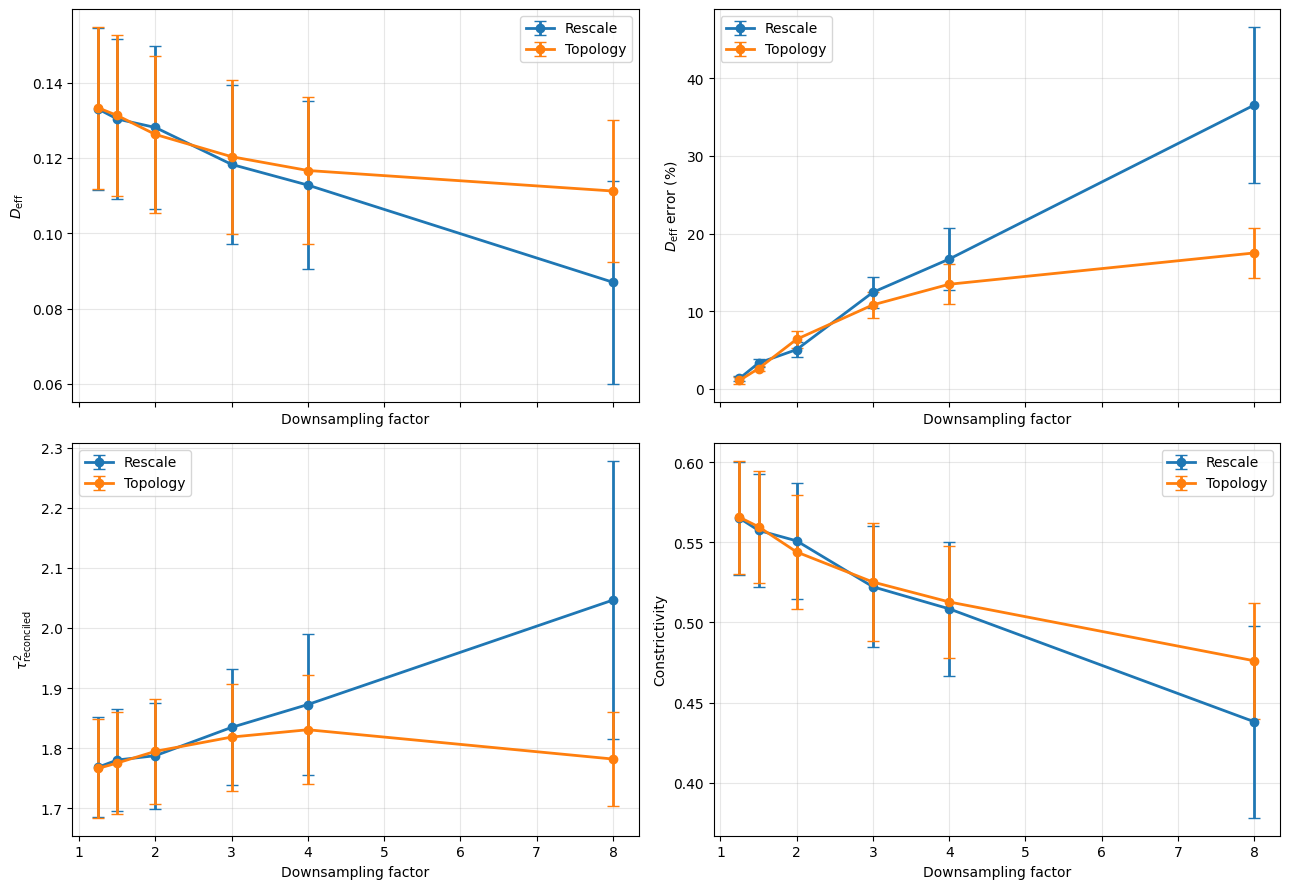

In [ ]:
methods = ["rescale", "topology"]

if "_multi_downsampling_cache" not in globals():
    _multi_downsampling_cache = {}

multi_records = []

for file_path in files:
    binary = np.load(file_path) == 3
    microstructure = file_path.split("/")[-2]

    original_result = solve_taufactor(
        binary,
        transport_axis=0,
        periodic=False,
        save_full=False,
    )
    reference_d_eff = original_result["D_eff"]

    for factor in factors:
        cache_key = (file_path, float(factor))

        if cache_key not in _multi_downsampling_cache:
            _multi_downsampling_cache[cache_key] = compare_downsampling(
                binary,
                factor=factor,
                transport_axis=0,
                match_volume_fraction=False,
                paths_per_component=12,
                seed=0,
            )

        factor_outputs, _ = _multi_downsampling_cache[cache_key]

        for method in methods:
            result = solve_taufactor(
                factor_outputs[method],
                transport_axis=0,
                periodic=False,
                save_full=False,
            )

            multi_records.append({
                "microstructure": microstructure,
                "file": file_path,
                "factor": float(factor),
                "method": method,
                "D_eff": result["D_eff"],
                "D_eff_error_percent": (
                    abs(result["D_eff"] - reference_d_eff)
                    / abs(reference_d_eff)
                    * 100
                ),
                "tau_reconciled_squared": (
                    result["tau_reconciled"] ** 2
                ),
                "constrictivity": result["constrictivity"],
            })

df_multi_transport = pd.DataFrame(multi_records)

metrics = [
    ("D_eff", r"$D_{\mathrm{eff}}$"),
    ("D_eff_error_percent", r"$D_{\mathrm{eff}}$ error (%)"),
    ("tau_reconciled_squared", r"$\tau_{\mathrm{reconciled}}^2$"),
    ("constrictivity", "Constrictivity"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
axes = axes.ravel()

for ax, (metric, ylabel) in zip(axes, metrics):
    for method, group in df_multi_transport.groupby("method"):
        stats = (
            group.groupby("factor")[metric]
            .agg(["mean", "std"])
            .reset_index()
            .sort_values("factor")
        )

        ax.errorbar(
            stats["factor"],
            stats["mean"],
            yerr=stats["std"],
            marker="o",
            capsize=4,
            linewidth=2,
            label=method.capitalize(),
        )

    ax.set_xlabel("Downsampling factor")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

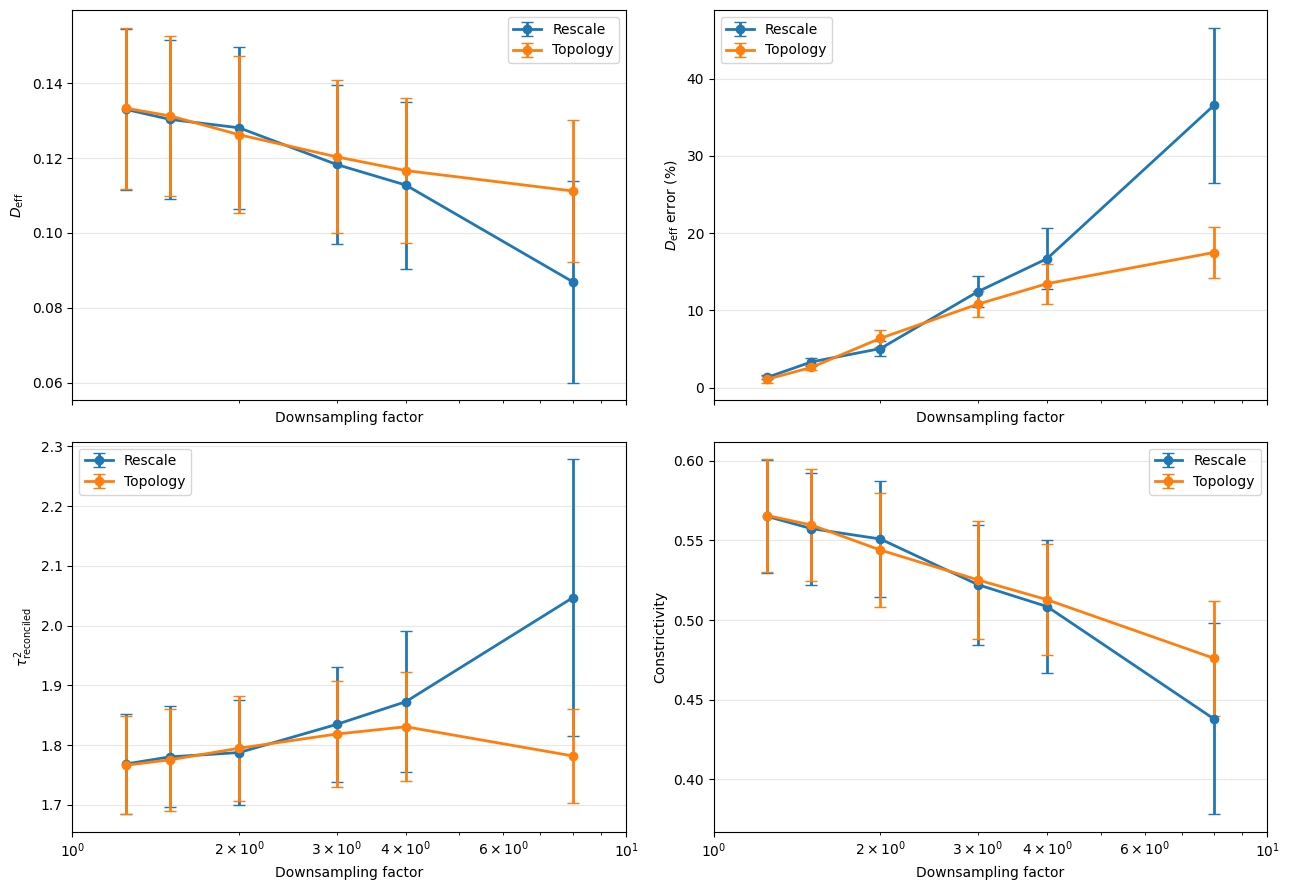

In [57]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
axes = axes.ravel()

for ax, (metric, ylabel) in zip(axes, metrics):
    for method, group in df_multi_transport.groupby("method"):
        stats = (
            group.groupby("factor")[metric]
            .agg(["mean", "std"])
            .reset_index()
            .sort_values("factor")
        )

        ax.errorbar(
            stats["factor"],
            stats["mean"],
            yerr=stats["std"],
            marker="o",
            capsize=4,
            linewidth=2,
            label=method.capitalize(),
        )

    ax.set_xlabel("Downsampling factor")
    ax.set_ylabel(ylabel)
    ax.set_xscale("log")
    ax.set_xlim(1, 10)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()